## Aligning world-landmark hand model with holistic hand model

In [1]:
import os
import glob
import pandas as pd

curfolder = os.getcwd()
processedfolder = os.path.join(curfolder, 'Output_Timeseries')
#_handModel_world
outputcsv = glob.glob(os.path.join(processedfolder, '*_handModel_world*.csv'))  # Ensure outtputf_ts is defined
print(f"Found {len(outputcsv)} files matching the pattern.")


Found 12398 files matching the pattern.


# Getting world landmark files into common format

In [39]:
import pandas as pd
import numpy as np

errors = []

def rename_cols(df, side):
    renamed = {}
    for c in df.columns:
        if c.startswith("X_"):
            renamed[c] = c.replace("X_", f"X_{side}_")
        elif c.startswith("Y_"):
            renamed[c] = c.replace("Y_", f"Y_{side}_")
        elif c.startswith("Z_"):
            renamed[c] = c.replace("Z_", f"Z_{side}_")
    return df.rename(columns=renamed)

for hand_path in outputcsv:

    try:
        df = pd.read_csv(hand_path)
    except Exception as e:
        print(f"⚠️ Failed to read {hand_path}: {e}")
        errors.append(('read error', hand_path))
        continue

    # check if X_LEFT_WRIST exists, if so skip
    if "X_LEFT_WRIST" in df.columns:
        print(f"Skipping {hand_path} because it already has been processed.")
        continue

    print(f"Processing {hand_path}...")

    # get the sampling rate
    # sampling_rate = 1 / df["time"].diff().median()
    # dt = 1 / sampling_rate
    # print(f"Processing {hand_path} with sampling rate {sampling_rate:.2f} Hz")
    # print(dt)
    unique_times = np.sort(df["time"].dropna().unique())
    time_diffs = np.diff(unique_times)
    
    if len(time_diffs) == 0 or np.median(time_diffs) <= 0:
        print(f"⚠️ {hand_path}: invalid timing, falling back to 20 ms.")
        # append
        errors.append(('invalid timing', hand_path))
        continue
        #break
    else:
        dt = float(np.median(time_diffs))
    #break

    # Keep only relevant columns
    landmark_cols = [c for c in df.columns if c.startswith(("X_", "Y_", "Z_"))]
    df = df[["time", "hand", "confidence"] + landmark_cols]

    # Drop rows where no hand is detected
    df = df.dropna(subset=["hand"])

    # Make hand column string-safe
    df["hand"] = df["hand"].astype(str)

    # min time in df
    original_start_time = df["time"].min()
    original_end_time = df["time"].max()

    # Split left/right
    left = df[df["hand"].str.contains("left", case=False, na=False)].copy()
    right = df[df["hand"].str.contains("right", case=False, na=False)].copy()

    left = rename_cols(left, "LEFT")
    right = rename_cols(right, "RIGHT")

    # Rename confidence
    left = left.rename(columns={"confidence": "CONF_LEFT_HAND"})
    right = right.rename(columns={"confidence": "CONF_RIGHT_HAND"})

    # Drop hand label
    left = left.drop(columns=["hand"])
    right = right.drop(columns=["hand"])

    # Deduplicate in case MediaPipe emitted multiple rows per frame
    left = left.sort_values("time").drop_duplicates(subset=["time"])
    right = right.sort_values("time").drop_duplicates(subset=["time"])

    # Merge into one row per frame (only where at least one hand exists)
    merged = pd.merge(left, right, on="time", how="outer")

    # Build exact time grid from original start/end
    full_time = np.arange(original_start_time, original_end_time + dt/2, dt)
    full_df = pd.DataFrame({"time": full_time})

    # Merge with full time grid to fill in missing frames
    full_df = pd.merge(full_df, merged, on="time", how="left")

    # save instead the original
    full_df.to_csv(hand_path, index=False)
       
    #break




Skipping e:\GtST_FLESH_KinTrajectory\Output_Timeseries\GP02_(AUF)PUMPEN.mp4_handModel_world.csv because it already has been processed.
Skipping e:\GtST_FLESH_KinTrajectory\Output_Timeseries\GP02_ABEND.mp4_handModel_world.csv because it already has been processed.
Skipping e:\GtST_FLESH_KinTrajectory\Output_Timeseries\GP02_ABHOLEN.mp4_handModel_world.csv because it already has been processed.
Skipping e:\GtST_FLESH_KinTrajectory\Output_Timeseries\GP02_ABLEHNEN.mp4_handModel_world.csv because it already has been processed.
Skipping e:\GtST_FLESH_KinTrajectory\Output_Timeseries\GP02_ABTROCKNEN .mp4_handModel_world.csv because it already has been processed.
Skipping e:\GtST_FLESH_KinTrajectory\Output_Timeseries\GP02_ADLER.mp4_handModel_world.csv because it already has been processed.
Skipping e:\GtST_FLESH_KinTrajectory\Output_Timeseries\GP02_AFFE.mp4_handModel_world.csv because it already has been processed.
Skipping e:\GtST_FLESH_KinTrajectory\Output_Timeseries\GP02_AKKORDEON.mp4_handMod

In [41]:
full_df.head()

,time,CONF_LEFT_HAND,X_LEFT_WRIST,Y_LEFT_WRIST,Z_LEFT_WRIST,X_LEFT_THUMB_CMC,Y_LEFT_THUMB_CMC,Z_LEFT_THUMB_CMC,X_LEFT_THUMB_MCP,Y_LEFT_THUMB_MCP,...,Z_RIGHT_PINKY_MCP,X_RIGHT_PINKY_PIP,Y_RIGHT_PINKY_RIGHT_PIP,Z_RIGHT_PINKY_PIP,X_RIGHT_PINKY_DIP,Y_RIGHT_PINKY_RIGHT_DIP,Z_RIGHT_PINKY_DIP,X_RIGHT_PINKY_TIP,Y_RIGHT_PINKY_RIGHT_TIP,Z_RIGHT_PINKY_TIP
0,0.0,score: 0.993520558,-0.009256,-0.000732,0.077565,0.004717,-0.005339,0.056648,0.016205,0.000292,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,20.0,score: 0.997490287,-0.008145,0.003644,0.078631,0.004094,-0.003572,0.058046,0.014402,0.005102,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,40.0,score: 0.995699644,-0.010209,0.003269,0.078882,0.001603,-0.004080,0.057469,0.012565,0.003691,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,60.0,score: 0.996155381,-0.005858,0.004640,0.076711,0.006529,-0.001526,0.056676,0.015034,0.006089,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,80.0,score: 0.995145,-0.005130,0.005275,0.079907,0.006340,-0.001508,0.058596,0.014701,0.005090,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [43]:
print(len(errors))
errors

23


[('invalid timing',
  'e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\GP05_BESUCHEN.mp4_handModel_world.csv'),
 ('invalid timing',
  'e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\GP05_PAUSE.mp4_handModel_world.csv'),
 ('invalid timing',
  'e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\GP08_KUESSEN.mp4_handModel_world.csv'),
 ('invalid timing',
  'e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\GP08_VERSUCHEN.mp4_handModel_world.csv'),
 ('read error',
  'e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\GP10_HAHN .mp4_handModel_world.csv'),
 ('invalid timing',
  'e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\GP17_ANFANG.mp4_handModel_world.csv'),
 ('invalid timing',
  'e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\GP17_BERUF.mp4_handModel_world.csv'),
 ('invalid timing',
  'e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\GP17_DAUMEN DRUECKEN.mp4_handModel_world.csv'),
 ('read error',
  'e:\\GtST_FLESH_KinTrajectory\\Output_Timeseries\\GP17_FRAU.mp4_handModel_world.csv'),

# Exploring overlap of holistic and hand-specific models

Sample hand file: e:\GtST_FLESH_KinTrajectory\Output_Timeseries\GP10_EINFACH.mp4_handModel_world.csv


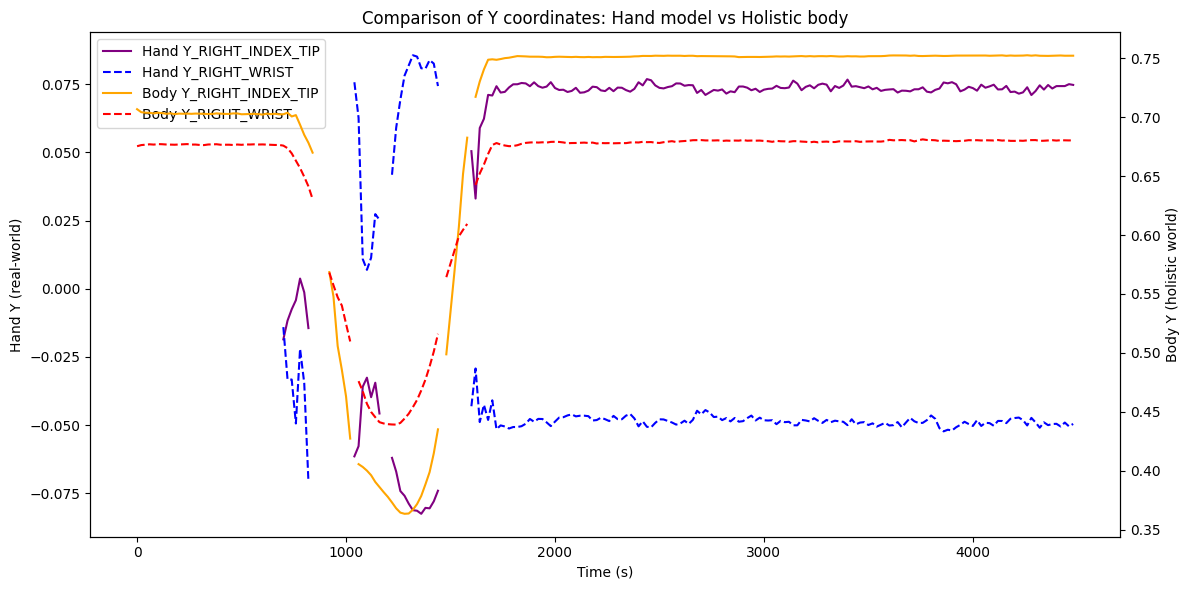

In [60]:

from turtle import color


sample_hand = outputcsv[1500]
print(f"Sample hand file: {sample_hand}")

sample_body_name = os.path.basename(sample_hand).replace("handModel_world", "hands_hol")
sample_body = os.path.join(processedfolder, sample_body_name)

df_hand = pd.read_csv(sample_hand)
df_body = pd.read_csv(sample_body)

fig, ax_hand = plt.subplots(figsize=(12, 6))
ax_body = ax_hand.twinx()

# Hand model (left y-axis)
ax_hand.plot(df_hand["time"], df_hand["Y_RIGHT_INDEX_TIP"], label="Hand Y_RIGHT_INDEX_TIP", color="purple")
ax_hand.plot(df_hand["time"], df_hand["Y_RIGHT_WRIST"], label="Hand Y_RIGHT_WRIST", linestyle="--", color="blue")
ax_hand.set_ylabel("Hand Y (real-world)")

# Body / Holistic model (right y-axis)
ax_body.plot(df_body["time"], df_body["Y_RIGHT_INDEX_FINGER_TIP"], label="Body Y_RIGHT_INDEX_TIP", color="orange")
ax_body.plot(df_body["time"], df_body["Y_RIGHT_WRIST"], label="Body Y_RIGHT_WRIST", linestyle="--", color="red")
ax_body.set_ylabel("Body Y (holistic world)")

# Shared x-axis
ax_hand.set_xlabel("Time (s)")
ax_hand.set_title("Comparison of Y coordinates: Hand model vs Holistic body")

# Combine legends
lines_hand, labels_hand = ax_hand.get_legend_handles_labels()
lines_body, labels_body = ax_body.get_legend_handles_labels()
ax_hand.legend(lines_hand + lines_body, labels_hand + labels_body, loc="best")

plt.tight_layout()
plt.show()

# TODO: interpolate and show difference in final timeseries

We see lots of droup-outs for the hand model. Given that these are finger keypoints we are interested in, temporal consistency is preferred over absolute units. The gaps and jitter could blown up the pipeline down the stream.

What we do instead is to calculate distance of two bones per participant/per file and then choose median value per participant and this use later for holistic model to scale the units. 

In [81]:
def estimate_scale_per_file(df_realworld, df_pixels, min_valid_frames=50):
    # valid frames: both pipelines present
    valid = (
        (~df_realworld["X_RIGHT_WRIST"].isna()) &
        (~df_realworld["X_RIGHT_INDEX_RIGHT_MCP"].isna()) &
        (~df_pixels["X_RIGHT_WRIST"].isna()) &
        (~df_pixels["X_RIGHT_INDEX_FINGER_MCP"].isna())
    )

    if valid.sum() < min_valid_frames:
        return None  # not enough data

    hand_len_m = np.sqrt(
        (df_realworld["X_RIGHT_INDEX_RIGHT_MCP"] - df_realworld["X_RIGHT_WRIST"])**2 +
        (df_realworld["Y_RIGHT_INDEX_MCP"] - df_realworld["Y_RIGHT_WRIST"])**2 +
        (df_realworld["Z_RIGHT_INDEX_MCP"] - df_realworld["Z_RIGHT_WRIST"])**2
    )

    body_len_px = np.sqrt(
        (df_pixels["X_RIGHT_INDEX_FINGER_MCP"] - df_pixels["X_RIGHT_WRIST"])**2 +
        (df_pixels["Y_RIGHT_INDEX_FINGER_MCP"] - df_pixels["Y_RIGHT_WRIST"])**2
    )

    scale = np.nanmedian(hand_len_m[valid] / body_len_px[valid])
    return scale


In [88]:
from numpy import real
from collections import defaultdict


errors = []
holistic_files = glob.glob(os.path.join(processedfolder, '*hands_hol*.csv'))
# get rid of flipped and video_raw files
holistic_files = [f for f in holistic_files if "flipped" not in f and "video_raw" not in f]

participant_scales = defaultdict(list)

for file in holistic_files:
    print('working on ', file)

    participant_id = os.path.basename(file).split('_')[0]

    # find corresponding real-world hand file
    base_name = os.path.basename(file).replace("hands_hol", "handModel_world")
    realworld_file = os.path.join(processedfolder, base_name)
    if not os.path.exists(realworld_file):
        print(f"⚠️ No matching hand file for {file}")
        errors.append(('missing hand file', file))
        continue

    df_hol = pd.read_csv(file)
    try:
        df_real = pd.read_csv(realworld_file)
    except Exception as e:
        print(f"⚠️ Failed to read {realworld_file}: {e}")
        errors.append(('read error', realworld_file))
        continue

    try:
        scale = estimate_scale_per_file(df_real, df_hol)
        if scale is not None and np.isfinite(scale):
            participant_scales[participant_id].append(scale)
    except Exception as e:
        print(f"⚠️ Error processing {file}: {e}")
        errors.append(('processing error', file))
        continue

    #break





working on  e:\GtST_FLESH_KinTrajectory\Output_Timeseries\GP02_(AUF)PUMPEN.mp4_hands_hol.csv
working on  e:\GtST_FLESH_KinTrajectory\Output_Timeseries\GP02_ABEND.mp4_hands_hol.csv
working on  e:\GtST_FLESH_KinTrajectory\Output_Timeseries\GP02_ABHOLEN.mp4_hands_hol.csv
working on  e:\GtST_FLESH_KinTrajectory\Output_Timeseries\GP02_ADLER.mp4_hands_hol.csv
working on  e:\GtST_FLESH_KinTrajectory\Output_Timeseries\GP02_ABLEHNEN.mp4_hands_hol.csv
working on  e:\GtST_FLESH_KinTrajectory\Output_Timeseries\GP02_AFFE.mp4_hands_hol.csv
working on  e:\GtST_FLESH_KinTrajectory\Output_Timeseries\GP02_ABTROCKNEN .mp4_hands_hol.csv
working on  e:\GtST_FLESH_KinTrajectory\Output_Timeseries\GP02_AKKORDEON.mp4_hands_hol.csv
working on  e:\GtST_FLESH_KinTrajectory\Output_Timeseries\GP02_ALT.mp4_hands_hol.csv
working on  e:\GtST_FLESH_KinTrajectory\Output_Timeseries\GP02_ANFANG.mp4_hands_hol.csv
working on  e:\GtST_FLESH_KinTrajectory\Output_Timeseries\GP02_ANGELN.mp4_hands_hol.csv
working on  e:\GtST_FLE

In [91]:
# what is the variance per participant?
for participant, scales in participant_scales.items():
    if len(scales) > 0:
        print(f"Participant {participant}: mean scale = {np.mean(scales):.4f}, median = {np.median(scales):.4f}, std = {np.std(scales):.4f}, n = {len(scales)}")

Participant GP02: mean scale = 2.3948, median = 2.3088, std = 0.5347, n = 332
Participant GP05: mean scale = 3.0734, median = 2.8790, std = 0.9404, n = 167
Participant GP06: mean scale = 3.2294, median = 3.1346, std = 1.1855, n = 330
Participant GP08: mean scale = 4.7557, median = 4.2800, std = 2.4054, n = 319
Participant GP10: mean scale = 3.2761, median = 2.8389, std = 1.4551, n = 341
Participant GP11: mean scale = 3.1875, median = 3.0450, std = 0.8958, n = 359
Participant GP14: mean scale = 2.7749, median = 2.7424, std = 0.6042, n = 306
Participant GP17: mean scale = 3.6996, median = 3.5813, std = 1.1971, n = 182
Participant GP18: mean scale = 2.8579, median = 2.6441, std = 0.8124, n = 359
Participant GP01: mean scale = 2.6177, median = 2.4587, std = 0.7358, n = 347
Participant GP03: mean scale = 2.0274, median = 1.8990, std = 0.5863, n = 347
Participant GP15: mean scale = 3.9171, median = 3.4448, std = 1.8188, n = 361
Participant LP14: mean scale = 1.0588, median = 0.9617, std = 0.

Ok, this further discourage us to use the real-world units. The SDs are sometimes big and there is a big variance across participants, even at those where the camera positioning was the same (within IP; LP or GP group, for instance).

To retain accuracy, we will continue with data from holistic model where units are pixels. We will, however, normalize by centering on palm of the hand

# Inspection via animation

In [3]:
holistic_files = glob.glob(os.path.join(processedfolder, '*hands_hol*.csv'))
print(f"Found {len(holistic_files)} holistic hand files.")

Found 12398 holistic hand files.


In [116]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.animation import FuncAnimation
from IPython.display import Video

# Load CSV file
fileexample = holistic_files[8000]
MT_tracking = pd.read_csv(fileexample)

# Interpolate
MT_tracking = MT_tracking.interpolate(method='linear', limit_direction='both')

print("Missing values after interpolation:")
print(MT_tracking.isna().sum().sum())

# -------------------------------
# Precompute aligned X/Y/Z columns
# -------------------------------
x_cols = [c for c in MT_tracking.columns if c.startswith("X_")]
y_cols = [c for c in MT_tracking.columns if c.startswith("Y_")]
z_cols = [c for c in MT_tracking.columns if c.startswith("Z_")]

x_map = {c[2:]: c for c in x_cols}
y_map = {c[2:]: c for c in y_cols}
z_map = {c[2:]: c for c in z_cols}

common_kps = sorted(set(x_map) & set(y_map) & set(z_map))

X_COLS = [x_map[k] for k in common_kps]
Y_COLS = [y_map[k] for k in common_kps]
Z_COLS = [z_map[k] for k in common_kps]

print(f"Plotting {len(common_kps)} keypoints")

# -------------------------------
# Create figure and animation
# -------------------------------
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')

num_frames = len(MT_tracking)

def update(frame):
    ax.clear()
    ax.set_xlabel('X')
    ax.set_ylabel('Z')
    ax.set_zlabel('Y')
    ax.set_title('3D Animation')

    # Adjust these limits to your coordinate system
    ax.set_xlim3d(0.5, 0.8)
    ax.set_ylim3d(20, 10)
    ax.set_zlim3d(0, 1)

    row = MT_tracking.iloc[frame]

    x = row[X_COLS].values.astype(float)
    y = row[Z_COLS].values.astype(float)      # Z → Y axis
    z = -row[Y_COLS].values.astype(float)     # flip vertical

    scatter = ax.scatter(x, y, z, c='red', s=20)
    return scatter,

ani = FuncAnimation(fig, update, frames=num_frames, interval=1000/30)

plt.close(fig)

# Save the animation
out_path = '3D_animation_hand_check.mp4'
ani.save(out_path, writer='ffmpeg')

# Display the animation
Video(out_path, embed=True, width=800)


Missing values after interpolation:
0
Plotting 42 keypoints


# Processing

- inverting
- interpolation
- smoothing
- deriving
- distances

In [30]:
sample_file = holistic_files[8000]
print(f"Sample holistic hand file: {sample_file}")
sample_df = pd.read_csv(sample_file)
sample_df.head()

Sample holistic hand file: e:\GtST_FLESH_KinTrajectory\Output_Timeseries\LP13_01_AUTO.mp4_hands_hol.csv


,time,X_LEFT_WRIST,Y_LEFT_WRIST,Z_LEFT_WRIST,X_LEFT_THUMB_CMC,Y_LEFT_THUMB_CMC,Z_LEFT_THUMB_CMC,X_LEFT_THUMB_MCP,Y_LEFT_THUMB_MCP,Z_LEFT_THUMB_MCP,...,Z_RIGHT_PINKY_FINGER_MCP,X_RIGHT_PINKY_FINGER_PIP,Y_RIGHT_PINKY_FINGER_PIP,Z_RIGHT_PINKY_FINGER_PIP,X_RIGHT_PINKY_FINGER_DIP,Y_RIGHT_PINKY_FINGER_DIP,Z_RIGHT_PINKY_FINGER_DIP,X_RIGHT_PINKY_FINGER_TIP,Y_RIGHT_PINKY_FINGER_TIP,Z_RIGHT_PINKY_FINGER_TIP
0,0.000000,0.510963,0.889344,1.486814e-07,0.494883,0.874244,-0.015726,0.474459,0.891075,-0.021132,...,-0.000131,0.433495,0.993531,-0.003207,0.446474,0.992944,-0.002451,0.455724,0.987967,-0.000871
1,33.333333,0.515311,0.890073,2.253013e-07,0.496434,0.876142,-0.015505,0.475971,0.889552,-0.021035,...,0.003244,0.429482,0.986529,-0.000248,0.443419,0.984238,-0.000292,0.453540,0.977467,0.000530
2,66.666667,0.514068,0.887578,2.320395e-07,0.495636,0.874114,-0.016542,0.474978,0.890210,-0.022153,...,0.003792,0.431524,0.984431,-0.000323,0.445577,0.981533,-0.001259,0.456033,0.974851,-0.001003
3,100.000000,0.514583,0.888043,2.295684e-07,0.495553,0.874668,-0.016205,0.474787,0.890231,-0.021682,...,0.003140,0.431946,0.984225,-0.001470,0.446444,0.980825,-0.002656,0.456855,0.973643,-0.002464
4,133.333333,0.514581,0.888184,2.307196e-07,0.495854,0.874436,-0.016345,0.475054,0.889865,-0.021958,...,0.004929,0.431726,0.983512,0.000688,0.446051,0.980280,-0.000502,0.456414,0.973124,-0.000393


## Interpolate

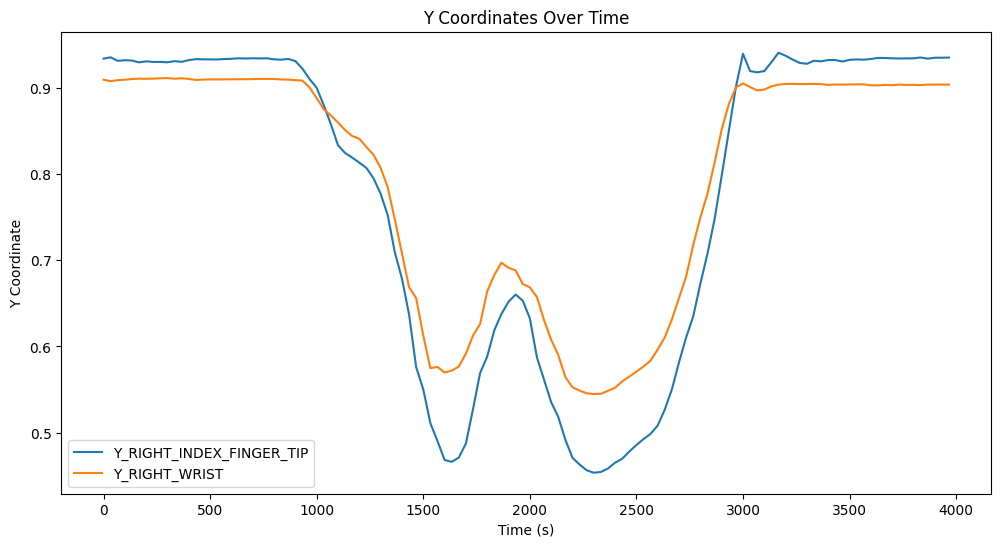

In [31]:
import matplotlib.pyplot as plt

# obtain column names
def interpolate(sample):
    cols = sample.columns
    #print(cols)

# put away time and fileID from cols
    cols = cols.drop(['time'])

# loop over the cols and interpolate missing data
    for col in cols:
        sample[col] = sample[col].interpolate(method='linear', x = sample['time'], limit=10, limit_direction='both')
    return sample

sample = interpolate(sample_df)

# plot to see if we need to invert Y
plt.figure(figsize=(12, 6))
plt.plot(sample['time'], sample['Y_RIGHT_INDEX_FINGER_TIP'], label='Y_RIGHT_INDEX_FINGER_TIP')
plt.plot(sample['time'], sample['Y_RIGHT_WRIST'], label='Y_RIGHT_WRIST')
plt.xlabel('Time (s)')
plt.ylabel('Y Coordinate')
plt.title('Y Coordinates Over Time')
plt.legend()
plt.show()

Yes, we need to invert

## Invert

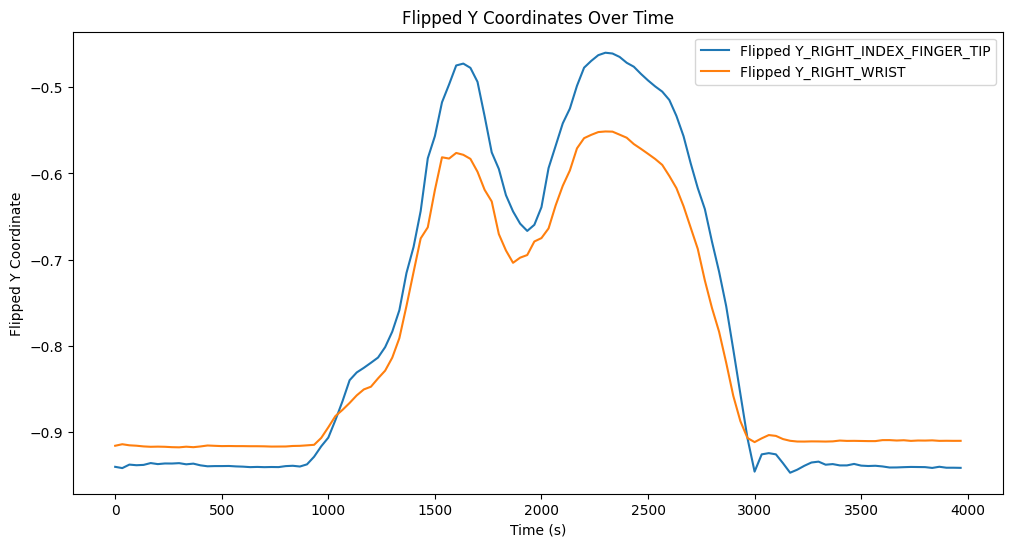

In [32]:
# flip the y-axis data (code modified from envisionbox)
def flip_data(df):
    df = df.copy()  # avoid modifying original dataframe directly
    cols = [col for col in df.columns if 'Y_' in col]

    # Get max y-value from the first frame
    maxpoint = max(df.loc[0, cols])

    # Flip all Y_ columns across all rows
    for joint in cols:
        df.loc[:, joint] = maxpoint - df[joint] - 1

    return df

sample = flip_data(sample)

# Plot
plt.figure(figsize=(12, 6))
plt.plot(sample['time'], sample['Y_RIGHT_INDEX_FINGER_TIP'], label='Flipped Y_RIGHT_INDEX_FINGER_TIP')
plt.plot(sample['time'], sample['Y_RIGHT_WRIST'], label='Flipped Y_RIGHT_WRIST')
plt.xlabel('Time (s)')
plt.ylabel('Flipped Y Coordinate')
plt.title('Flipped Y Coordinates Over Time')
plt.legend()
plt.show()

## Smooth

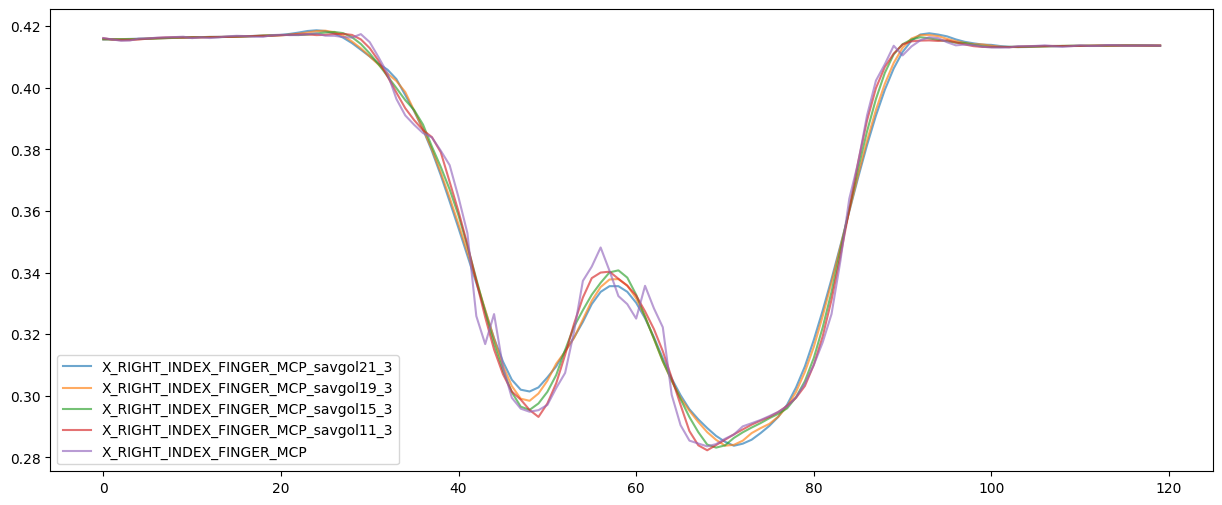

In [33]:
import scipy.signal

# test the different smoothing filter options - smoothing with savitzky-golay filter
x = 'X_RIGHT_INDEX_FINGER_MCP'
z = 'Z_RIGHT_INDEX_FINGER_MCP'
y = 'Y_RIGHT_INDEX_FINGER_MCP'

# list possible window
window = [21, 19, 15, 11]
# list possible orders
order = [3]

# col of interest
samplecol = [y, z, x]

# iterate over handcols and apply all possible combinations of window and order, save it to new df
# prepare new df
df_smooth = pd.DataFrame()

for col in samplecol:
    for win in window:
        for ord in order:
            df_smooth[col + '_savgol' + str(win) + '_' + str(ord)] = scipy.signal.savgol_filter(sample[col], win, ord)


# make R_Hand_x from df_sample a list
Keypoint_x = sample[x].tolist()
Keypoint_y = sample[y].tolist()
Keypoint_z = sample[z].tolist()


# load these values into df_smooth as a new column
df_smooth[x] = Keypoint_x
df_smooth[y] = Keypoint_y
df_smooth[z] = Keypoint_z

#plot all R_Hand_x columns in one plot
colstoplot = [col for col in df_smooth.columns if x in col]
plt.figure(figsize=(15, 6))
for col in colstoplot:
    # make plot bigger
    plt.plot(df_smooth[col], label=col, alpha=0.65)
plt.legend()
plt.show()




Let's do 11, 3

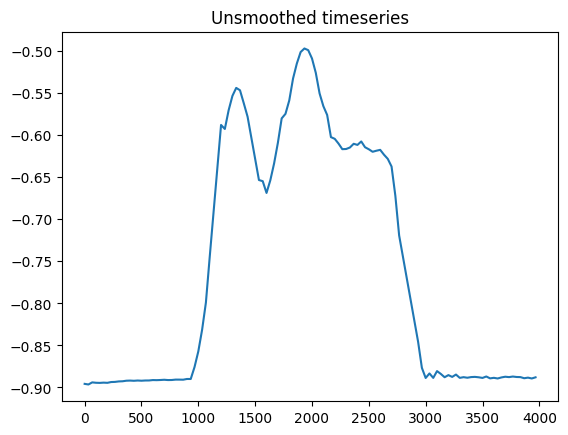

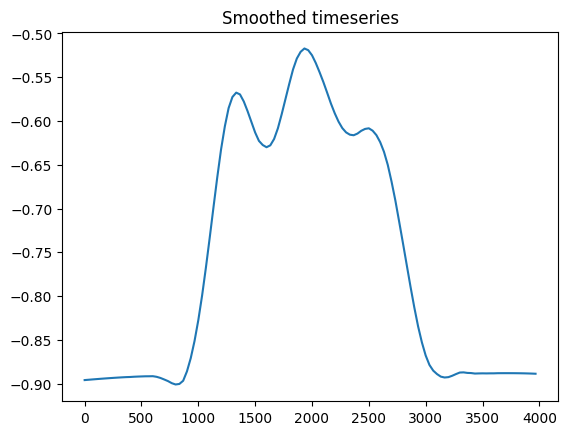

In [34]:
# obtain separate lists of the columns for the upper and lower body (face is included in upper body)

def smooth_data(sample):
    
    cols_to_smooth = [col for col in sample.columns if col.startswith(('X_', 'Y_', 'Z_'))]
    # smooth upperbody and face with savgol 11,3                            
    for col in cols_to_smooth:
        try:    
            sample[col] = scipy.signal.savgol_filter(sample[col], 21, 3)
        # if the window is smaller, make the window smaller
        except ValueError:
            try:
                sample[col] = scipy.signal.savgol_filter(sample[col], 15, 3)
            except ValueError:
                sample[col] = scipy.signal.savgol_filter(sample[col], 7, 3)

    return(sample)


plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.title('Unsmoothed timeseries')
plt.show()

sample = smooth_data(sample)

# plot the smoothed data
plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.title('Smoothed timeseries')
plt.show()

## Normalize

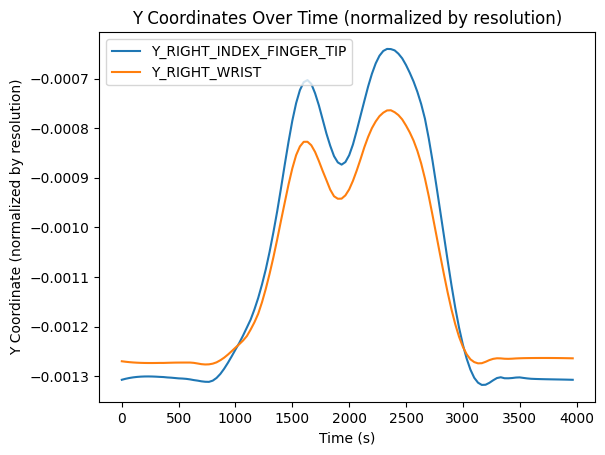

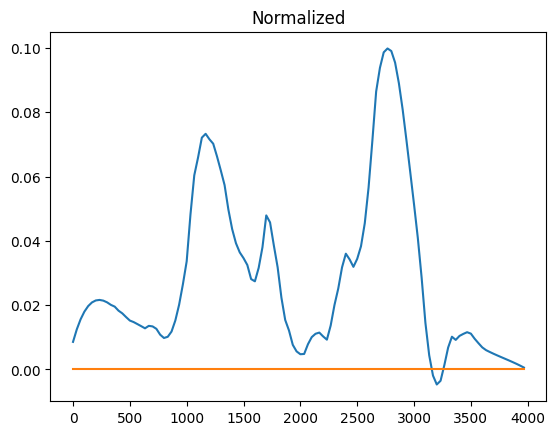

In [35]:
from tracemalloc import start
from turtle import width
import numpy as np

def normalize_by_resolution(df, width, height):
    out = df.copy()

    for c in df.columns:
        if c.startswith("X_"):
            out[c] = out[c] / width
        elif c.startswith("Y_"):
            out[c] = out[c] / height

    return out

def center_all_fingers(df, side="RIGHT"):

    out = df.copy()

    wrist = f"{side}_WRIST"

    mcp_keys = [
        f"{side}_INDEX_FINGER_MCP",
        f"{side}_MIDDLE_FINGER_MCP",
        f"{side}_RING_FINGER_MCP",
        f"{side}_PINKY_FINGER_MCP",
        f"{side}_THUMB_MCP"
    ]

    # 1) Center EVERYTHING on wrist
    for c in df.columns:
        if c.startswith(("X_", "Y_", "Z_")) and c[2:].startswith(side + "_"):
            axis = c[0]
            out[c] = df[c] - df[f"{axis}_{wrist}"]

    # 2) Center distal joints on MCPs (in the wrist-centered frame)
    for c in df.columns:
        if not c.startswith(("X_", "Y_", "Z_")):
            continue

        kp = c[2:]
        if not kp.startswith(side + "_"):
            continue

        if kp == wrist or kp in mcp_keys:
            continue

        if "_INDEX_" in kp:
            mcp = f"{side}_INDEX_FINGER_MCP"
        elif "_MIDDLE_" in kp:
            mcp = f"{side}_MIDDLE_FINGER_MCP"
        elif "_RING_" in kp:
            mcp = f"{side}_RING_FINGER_MCP"
        elif "_PINKY_" in kp:
            mcp = f"{side}_PINKY_FINGER_MCP"
        elif "_THUMB_" in kp:
            mcp = f"{side}_THUMB_MCP"
        else:
            continue

        axis = c[0]
        out[c] = out[c] - out[f"{axis}_{mcp}"]

    return out

def normalize_by_palmsize(df, side="RIGHT"):
    scale = np.sqrt(
        (df[f"X_{side}_INDEX_FINGER_MCP"] - df[f"X_{side}_PINKY_FINGER_MCP"])**2 +
        (df[f"Y_{side}_INDEX_FINGER_MCP"] - df[f"Y_{side}_PINKY_FINGER_MCP"])**2
    )

    for c in df.columns:
        if c.startswith((f"X_{side}_", f"Y_{side}_", f"Z_{side}_")):
            df[c] = df[c] / scale

    return df

fname = os.path.basename(sample_file)

# check if the basename starts with LP
if fname.startswith("LP"):
    width = 1280
    height = 720
elif fname.startswith("ViCom"):
    width = 1350
    height = 1080
else: 
    width = 1920
    height = 1080

sample = normalize_by_resolution(sample, width, height)
# plot right index tip (y) and right wrist (y) to see if centering is needed
plt.plot(sample['time'], sample['Y_RIGHT_INDEX_FINGER_TIP'], label='Y_RIGHT_INDEX_FINGER_TIP')
plt.plot(sample['time'], sample['Y_RIGHT_WRIST'], label='Y_RIGHT_WRIST')
plt.xlabel('Time (s)')
plt.ylabel('Y Coordinate (normalized by resolution)')
plt.title('Y Coordinates Over Time (normalized by resolution)')
plt.legend()
plt.show()

sample = center_all_fingers(sample, side="RIGHT")
sample = normalize_by_palmsize(sample, side="RIGHT")

# plot the centered data
plt.plot(sample['time'], sample['Y_RIGHT_INDEX_FINGER_TIP'])
plt.plot(sample['time'], sample['Y_RIGHT_WRIST'])
plt.title('Normalized')
plt.show()


## Derive speed, acceleration and jerk

In [36]:
def derive_speed_smooth(cols, sample, sr):
    speedcols = [col.replace('Y_', '').replace('X_', '').replace('Z_', '') for col in cols]
    speedcols = [col.replace('PINKF', 'PINKY_F').replace('INDEF', 'INDEX_F') for col in speedcols]
    speedcols = list(set(speedcols))  # keep only unique values

    # Get rid of all columns with visibility, and time
    speedcols = [col for col in speedcols if 'visibility' not in col and 'time' not in col]

    speed_dict = {}

    for col in speedcols:
        try:
            x = sample['X_' + col].to_numpy()
            y = sample['Y_' + col].to_numpy()
            z = sample['Z_' + col].to_numpy()

            speed = np.insert(np.sqrt(np.diff(x)**2 + np.diff(y)**2 + np.diff(z)**2), 0, 0)
            speed = np.abs(speed)
            try:
                speed = scipy.signal.savgol_filter(speed, 21, 3)
            except ValueError:
                try:
                    speed = scipy.signal.savgol_filter(speed, 15, 3)
                except ValueError:
                    speed = scipy.signal.savgol_filter(speed, 7, 3)
            speed = speed * sr  # convert to units per second
            speed_dict[col + '_speed'] = speed
            
        except KeyError:
            print(f"Skipping {col}: missing data")
            continue

    # Add all new speed columns at once
    speed_df = pd.DataFrame(speed_dict)
    sample = pd.concat([sample.reset_index(drop=True), speed_df], axis=1)

    return sample

def derive_accel_smooth(speedcols, sample):

    new_accel_cols = {}

    for col in speedcols:
        newcolname = col.replace('speed', 'acceleration')
        accel = np.insert(np.diff(sample[col]), 0, 0)
        try:
            accel = scipy.signal.savgol_filter(accel, 21, 3)
        except ValueError:
            try:
                accel = scipy.signal.savgol_filter(accel, 15, 3)
            except ValueError:
                accel = scipy.signal.savgol_filter(accel, 7, 3)
        new_accel_cols[newcolname] = accel

    # Efficiently add all acceleration columns at once
    sample = pd.concat([sample, pd.DataFrame(new_accel_cols, index=sample.index)], axis=1)
    return sample

def derive_jerk_smooth(sample):

    # Find acceleration columns
    accols = [col for col in sample.columns if '_acceleration' in col]

    new_jerk_cols = {}

    for col in accols:
        newcolname = col.replace('acceleration', 'jerk')
        jerk = np.insert(np.diff(sample[col]), 0, 0)
        try:    
            jerk = scipy.signal.savgol_filter(jerk, 21, 3)
        except ValueError:
            try:
                jerk = scipy.signal.savgol_filter(jerk, 15, 3)
            except ValueError:
                jerk = scipy.signal.savgol_filter(jerk, 7, 3)
        new_jerk_cols[newcolname] = jerk

    # Efficiently concatenate all new jerk columns
    sample = pd.concat([sample, pd.DataFrame(new_jerk_cols, index=sample.index)], axis=1)
    return sample


# Use on sample
# get all cols with X_, Y_ or Z_ and put them in a list
cols = [col for col in sample.columns if col.startswith(('X_', 'Y_', 'Z_'))]
sample = derive_speed_smooth(cols, sample, sr=30)
sample = derive_accel_smooth([col for col in sample.columns if '_speed' in col], sample)
sample = derive_jerk_smooth(sample)



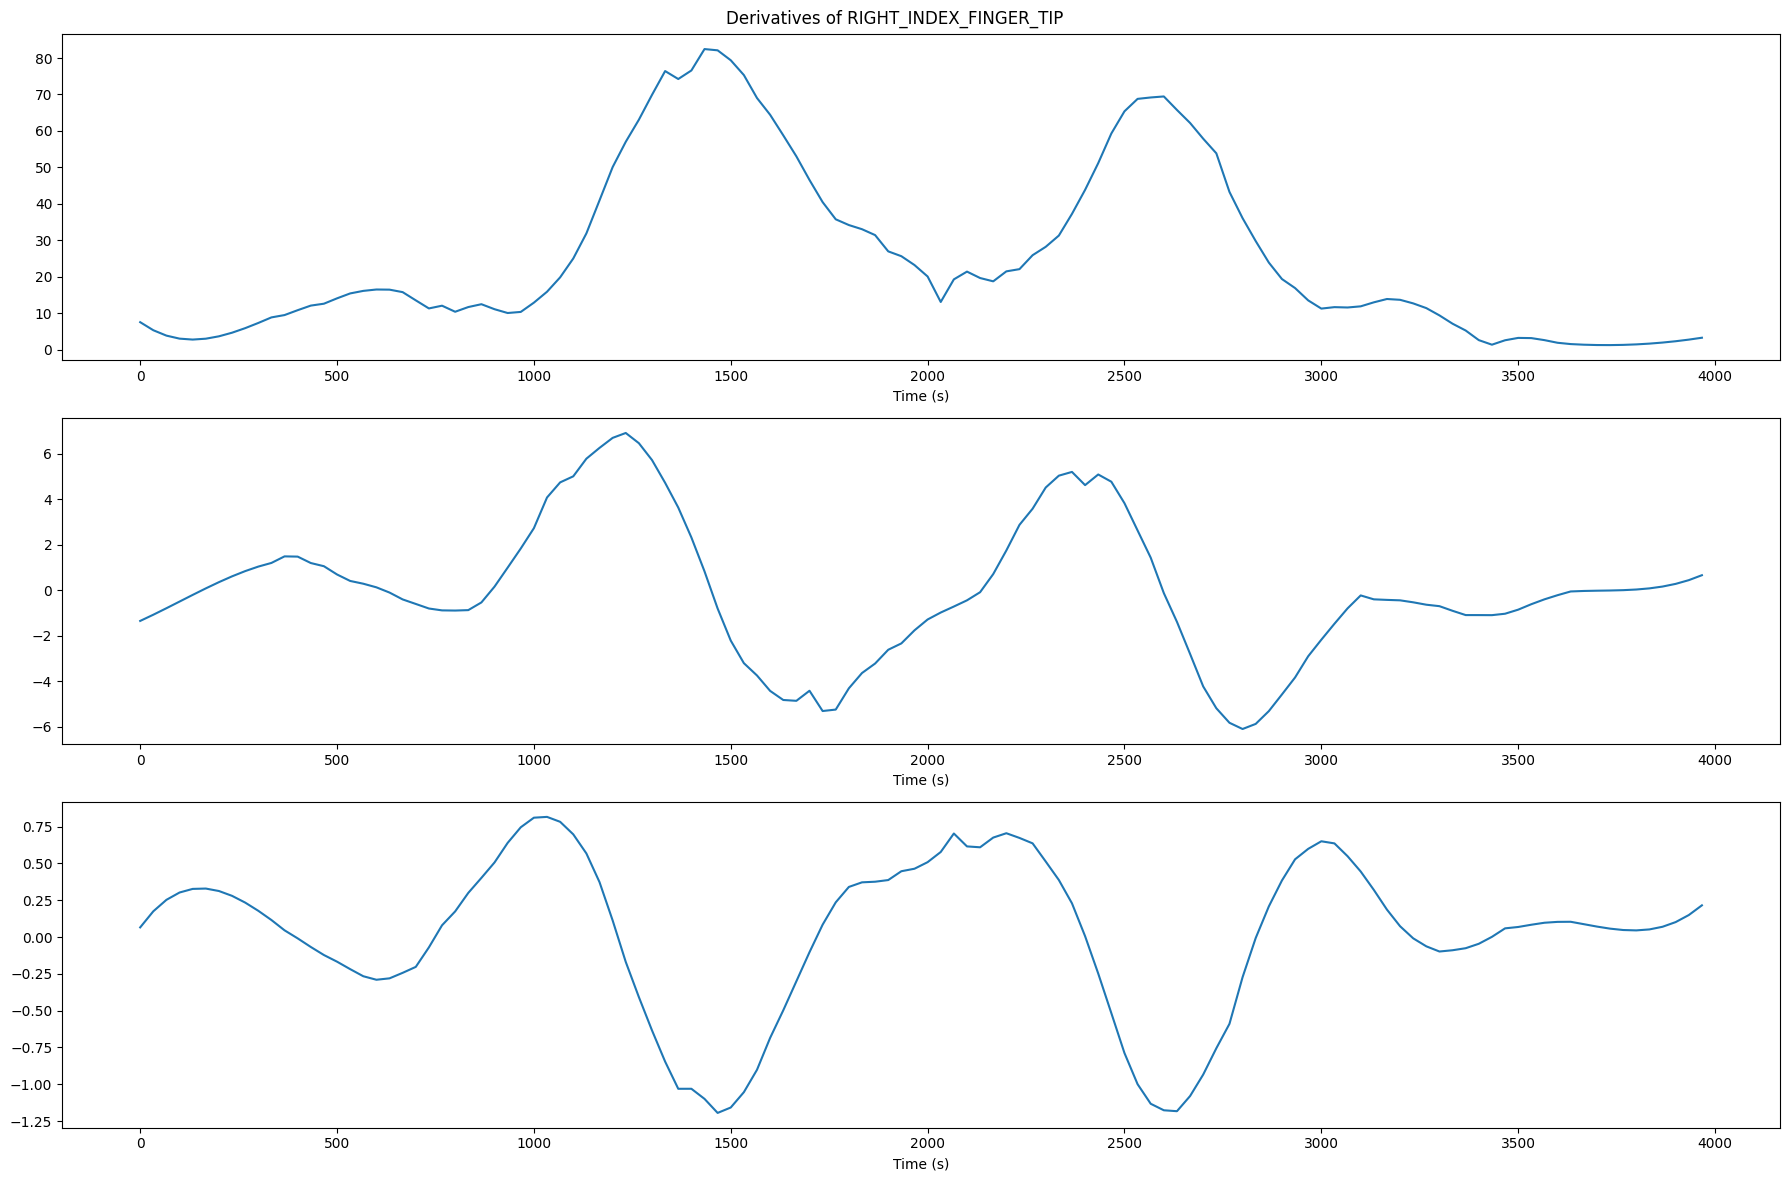

In [37]:
# Plot one column all thre derivates, each separate plot
plt.figure(figsize=(18, 12))
# Plot one column all thre derivates
plt.subplot(3, 1, 1)
plt.plot(sample['time'], sample['RIGHT_INDEX_FINGER_TIP_speed'], label='Speed')
plt.xlabel('Time (s)')
# Plot one column all thre derivates
plt.subplot(3, 1, 2)
plt.plot(sample['time'], sample['RIGHT_INDEX_FINGER_TIP_acceleration'], label='Acceleration')
plt.xlabel('Time (s)')
# Plot one column all thre derivates
plt.subplot(3, 1, 3)
plt.plot(sample['time'], sample['RIGHT_INDEX_FINGER_TIP_jerk'], label='Jerk')
plt.xlabel('Time (s)')
plt.suptitle('Derivatives of RIGHT_INDEX_FINGER_TIP')
plt.tight_layout()
plt.show()

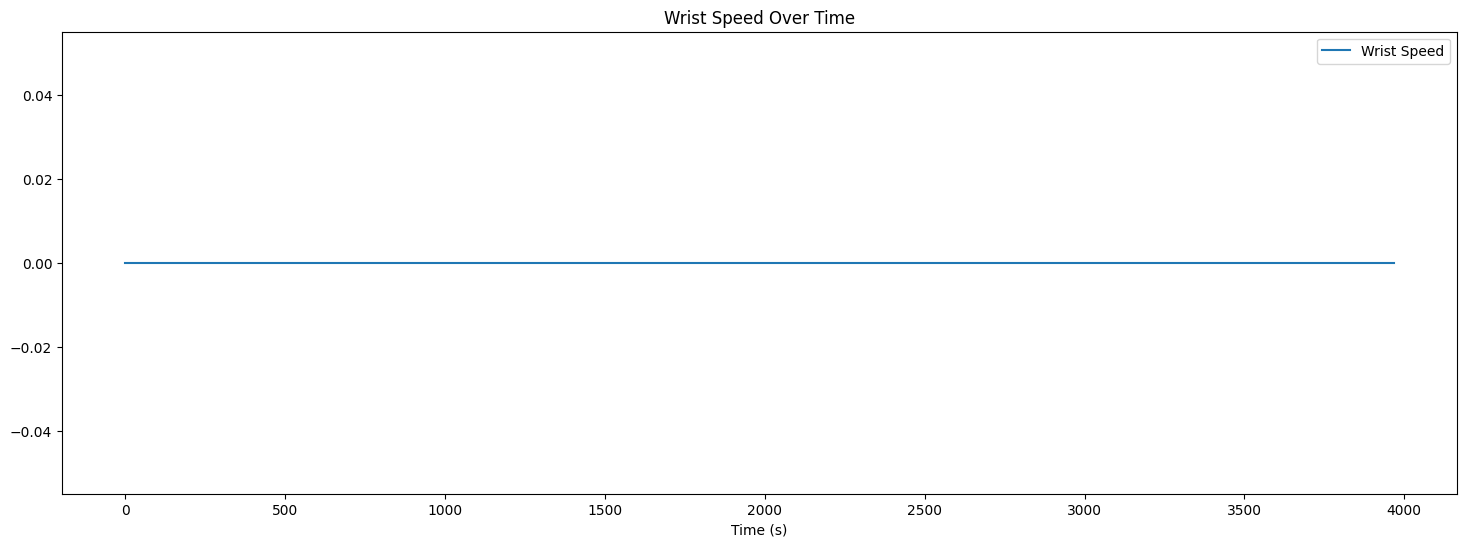

In [38]:
# plot also speed of wrist
plt.figure(figsize=(18, 6))
plt.plot(sample['time'], sample['RIGHT_WRIST_speed'], label='Wrist Speed')
plt.xlabel('Time (s)')
plt.title('Wrist Speed Over Time')
plt.legend()
plt.show()

This is exactly what we wanted - wrist is always at [0,0,0] so all movement is relative to this position

# Full loop - kinematics

In [40]:

errors_hand = []
outputfolder = os.path.join(curfolder, 'TS_processed')

for file in holistic_files:

    fname = os.path.basename(file)
    print('working on ', fname)

    # Load data
    df = pd.read_csv(file)

    # if df has no rows, skip
    if len(df) == 0:
        print(f"⚠️ {fname} is empty, skipping.")
        errors_hand.append(('empty file', fname))
        continue


    # Get resolution
    if fname.startswith("LP"):
        width = 1280
        height = 720
    elif fname.startswith("ViCom"):
        width = 1350
        height = 1080
    else: 
        width = 1920
        height = 1080

    # Get sampling rate
    if fname.startswith("LP") or fname.startswith("GtST"):
        sr = 30
    else:
        sr = 50


    # dt in ms
    dt_ms = 1000 / sr

    t0 = df["time"].min()
    t1 = df["time"].max()

    full_time = np.arange(t0, t1 + dt_ms/2, dt_ms)

    #df = pd.merge(pd.DataFrame({"time": full_time}), df, on="time", how="left")
    df_full = pd.DataFrame({"time": full_time})

    df_all = pd.concat([pd.DataFrame({"time": full_time}), df], ignore_index=True)

    # Keep only one row per timestamp (prefer real data over empty grid rows)
    df_all = (
        df_all
        .sort_values("time")
        .groupby("time", as_index=False)
        .first()
    )

    # interpolate
    df_all = interpolate(df_all)

    df = df_all[df_all["time"].isin(full_time)].reset_index(drop=True)
    #break

    # Interpolate missing values
    df = interpolate(df)
    

    # If there are still missing values, continue but append to error log
    if df.isna().sum().sum() > 0:
        print(f"⚠️ {fname} still has missing values after interpolation.")
        errors_hand.append(('missing values after interpolation', fname))
        #break

    #break
    try:
        # Flip Y axis 
        df = flip_data(df)
        # Smooth data
        # tr
        df = smooth_data(df)
        # Normalize by resolution
        df = normalize_by_resolution(df, width, height)
        # Center on palm
        df = center_all_fingers(df, side="RIGHT")
        df = center_all_fingers(df, side="LEFT")
        # Normalize by palm size
        df = normalize_by_palmsize(df, side="RIGHT")
        df = normalize_by_palmsize(df, side="LEFT")

        # Derive speed, acceleration, jerk
        df = derive_speed_smooth(df.columns, df, sr)
        df = derive_accel_smooth([col for col in df.columns if '_speed' in col], df)
        df = derive_jerk_smooth(df)



    except Exception as e:
        print(f"⚠️ Error processing {fname}: {e}")
        errors_hand.append(('processing error', fname))
        continue

    # add fileID column
    df['fileID'] = fname

    # Save processed file
    out_path = os.path.join(outputfolder, fname.replace("hands_hol", "hands_kinematics"))
    df.to_csv(out_path, index=False)
    #break


working on  GP02_(AUF)PUMPEN.mp4_hands_hol.csv
working on  GP02_ABEND.mp4_hands_hol.csv
working on  GP02_ABHOLEN.mp4_hands_hol.csv
working on  GP02_ADLER.mp4_hands_hol.csv
working on  GP02_ABLEHNEN.mp4_hands_hol.csv
working on  GP02_AFFE.mp4_hands_hol.csv
working on  GP02_ABTROCKNEN .mp4_hands_hol.csv
working on  GP02_AKKORDEON.mp4_hands_hol.csv
working on  GP02_ALT.mp4_hands_hol.csv
working on  GP02_ANFANG.mp4_hands_hol.csv
working on  GP02_ANGELN.mp4_hands_hol.csv
⚠️ GP02_ANGELN.mp4_hands_hol.csv still has missing values after interpolation.
working on  GP02_APFEL.mp4_hands_hol.csv
working on  GP02_ANGENEHM.mp4_hands_hol.csv
working on  GP02_ARM.mp4_hands_hol.csv
working on  GP02_ANSTECKEN.mp4_hands_hol.csv
working on  GP02_ATEM.mp4_hands_hol.csv
working on  GP02_ANTWORTEN.mp4_hands_hol.csv
working on  GP02_ARBEITEN.mp4_hands_hol.csv
working on  GP02_ATMEN.mp4_hands_hol.csv
working on  GP02_ARGUMENTIEREN.mp4_hands_hol.csv
working on  GP02_AUSWEIS.mp4_hands_hol.csv
working on  GP02_AV

In [41]:
# how many errros
print(f"Total files with errors: {len(errors_hand)}")

Total files with errors: 2760


In [42]:
# save it
errors_df = pd.DataFrame(errors_hand, columns=['error_type', 'file'])
errors_df.to_csv(os.path.join(outputfolder, 'hand_processing_errors.csv'), index=False)

Found 12389 kinematic hand files.


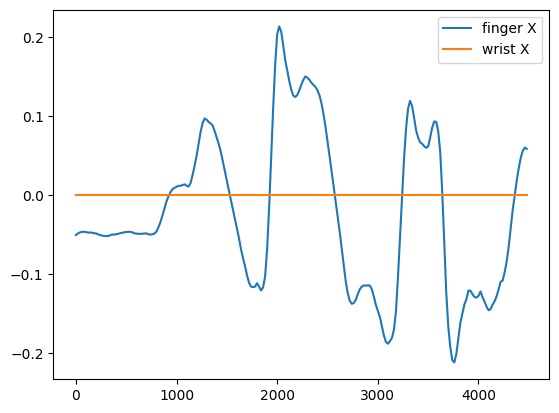

In [34]:
# load in one kinematics file and plot the X of index finger tip and wrist to see if they are centered
kinematic_files = glob.glob(os.path.join(outputfolder, '*hands_kinematics*.csv'))
print(f"Found {len(kinematic_files)} kinematic hand files.")
sample_kinematic_file = kinematic_files[0]
df = pd.read_csv(sample_kinematic_file)

plt.plot(df['time'], df['Y_RIGHT_INDEX_FINGER_TIP'], label='finger X')
plt.plot(df['time'], df['Y_RIGHT_WRIST'], label='wrist X')
plt.legend()


# Full loop - hand distances

In [43]:
def gethandjointdistance(sample, dictionary, joint1number, joint2number):

    # map the joint number to the joint name, based on the dictionary
    joint1 = dictionary[joint1number]
    joint2 = dictionary[joint2number]

    # left hand
    joint1x_l = sample['X_LEFT_' + joint1]
    joint1y_l = sample['Y_LEFT_' + joint1]
    joint1z_l = sample['Z_LEFT_' + joint1]

    joint2x_l = sample['X_LEFT_' + joint2]
    joint2y_l = sample['Y_LEFT_' + joint2]
    joint2z_l = sample['Z_LEFT_' + joint2]

    # right hand
    joint1x_r = sample['X_RIGHT_' + joint1]
    joint1y_r = sample['Y_RIGHT_' + joint1]
    joint1z_r = sample['Z_RIGHT_' + joint1]

    joint2x_r = sample['X_RIGHT_' + joint2]
    joint2y_r = sample['Y_RIGHT_' + joint2]
    joint2z_r = sample['Z_RIGHT_' + joint2]

    # get the x, y, z columns for both hands
    x1_l = joint1x_l
    y1_l = joint1y_l
    z1_l = joint1z_l
    x2_l = joint2x_l
    y2_l = joint2y_l
    z2_l = joint2z_l   

    x1_r = joint1x_r
    y1_r = joint1y_r
    z1_r = joint1z_r
    x2_r = joint2x_r
    y2_r = joint2y_r
    z2_r = joint2z_r 


    # calculate the distance for each dimension separately
    dist_x_l = x1_l - x2_l
    dist_y_l = y1_l - y2_l
    dist_z_l = z1_l - z2_l

    dist_x_r = x1_r - x2_r
    dist_y_r = y1_r - y2_r
    dist_z_r = z1_r - z2_r

    # calculate the total distance
    dist_l = np.sqrt(dist_x_l ** 2 + dist_y_l ** 2 + dist_z_l ** 2)
    dist_r = np.sqrt(dist_x_r ** 2 + dist_y_r ** 2 + dist_z_r ** 2)

    return dist_x_l, dist_y_l, dist_z_l, dist_l, dist_x_r, dist_y_r, dist_z_r, dist_r

# for each column that doesn't have _x, _y, _z, calculate speed, acceleration, and jerk

def derive_speed_accel_jerk(df, sr):
    cols = df.columns
    cols = cols.drop(['time', 'fileID'])
    for col in cols:
        if '_x' not in col and '_y' not in col and '_z' not in col:
            # calculate speed
            df[col + '_speed'] = np.insert(np.diff(df[col]), 0, 0)
            # absolutize
            df[col + '_speed'] = np.abs(df[col + '_speed'])
            # smooth it
            try:
                df[col + '_speed'] = scipy.signal.savgol_filter(df[col + '_speed'], 15, 3)
            except ValueError:
                df[col + '_speed'] = scipy.signal.savgol_filter(df[col + '_speed'], 7, 3)

            # convert to units per second
            df[col + '_speed'] = df[col + '_speed'] * sr
            # calculate acceleration
            df[col + '_acceleration'] = np.insert(np.diff(df[col + '_speed']), 0, 0)
            # smooth it
            try:
                df[col + '_acceleration'] = scipy.signal.savgol_filter(df[col + '_acceleration'], 15, 3)
            except ValueError:
                df[col + '_acceleration'] = scipy.signal.savgol_filter(df[col + '_acceleration'], 7, 3)
            # calculate jerk
            df[col + '_jerk'] = np.insert(np.diff(df[col + '_acceleration']), 0, 0)
            # smooth it
            try:
                df[col + '_jerk'] = scipy.signal.savgol_filter(df[col + '_jerk'], 15, 3)
            except ValueError:
                df[col + '_jerk'] = scipy.signal.savgol_filter(df[col + '_jerk'], 7, 3)

    return df

In [44]:
import warnings
warnings.filterwarnings("ignore")

hand_distances_error = []

# collect all processed files
processed_files = glob.glob(os.path.join(outputfolder, '*hands_kinematics*.csv'))

# create dictionary to map hand keypoint to a number
handkeypoints_mp = {'WRIST': 0, 'THUMB_CMC': 1, 'THUMB_MCP': 2, 'THUMB_IP': 3, 'THUMB_TIP': 4,
                 'INDEX_FINGER_MCP': 5, 'INDEX_FINGER_PIP': 6, 'INDEX_FINGER_DIP': 7, 'INDEX_FINGER_TIP': 8,
                 'MIDDLE_FINGER_MCP': 9, 'MIDDLE_FINGER_PIP': 10, 'MIDDLE_FINGER_DIP': 11, 'MIDDLE_FINGER_TIP': 12,
                 'RING_FINGER_MCP': 13, 'RING_FINGER_PIP': 14, 'RING_FINGER_DIP': 15, 'RING_FINGER_TIP': 16,
                 'PINKY_FINGER_MCP': 17, 'PINKY_FINGER_PIP': 18, 'PINKY_FINGER_DIP': 19, 'PINKY_FINGER_TIP': 20}

# make a dictionary that is flipped version of the handkeypoints
handkeypoints = {v: k for k, v in handkeypoints_mp.items()}

for file in processed_files:

    print('working on ', file)

    fname = os.path.basename(file)
    df = pd.read_csv(file)
    try:
        fileID = df['fileID'][0]
    except KeyError:
        hand_distances_error.append(('missing fileID column', file))
        continue

    # Get sr
    if fileID.startswith("LP") or fileID.startswith("GtST"):
        sr = 30
    else:
        sr = 50

    # get rid of all speed, velocity, acceleration, and jerk columns
    df = df.drop([col for col in df.columns if 'speed' in col], axis=1)
    df = df.drop([col for col in df.columns if 'velocity' in col], axis=1)
    df = df.drop([col for col in df.columns if 'acceleration' in col], axis=1)
    df = df.drop([col for col in df.columns if 'jerk' in col], axis=1)

    try:

        # get distance between 4-2, 4-1, 3-1, 4-17, 2-0, 3-0, 4-0 by finding the mapping of the keypoint to the number (for each hand)
        l4_2_x, l4_2_y, l4_2_z, l4_2, r4_2_x, r4_2_y, r4_2_z, r4_2 = gethandjointdistance(df, handkeypoints, 4, 2)
        l4_1_x, l4_1_y, l4_1_z, l4_1, r4_1_x, r4_1_y, r4_1_z, r4_1 = gethandjointdistance(df, handkeypoints, 4, 1)
        l3_1_x, l3_1_y, l3_1_z, l3_1, r3_1_x, r3_1_y, r3_1_z, r3_1 = gethandjointdistance(df, handkeypoints, 3, 1)
        l4_17_x, l4_17_y, l4_17_z, l4_17, r4_17_x, r4_17_y, r4_17_z, r4_17 = gethandjointdistance(df, handkeypoints, 4, 17)
        l2_0_x, l2_0_y, l2_0_z, l2_0, r2_0_x, r2_0_y, r2_0_z, r2_0 = gethandjointdistance(df, handkeypoints, 2, 0)
        l3_0_x, l3_0_y, l3_0_z, l3_0, r3_0_x, r3_0_y, r3_0_z, r3_0 = gethandjointdistance(df, handkeypoints, 3, 0)
        l4_0_x, l4_0_y, l4_0_z, l4_0, r4_0_x, r4_0_y, r4_0_z, r4_0 = gethandjointdistance(df, handkeypoints, 4, 0)

        # get distance between 8-6, 7-5, 8-5, 6-0, 7-0, 8-0
        l8_6_x, l8_6_y, l8_6_z, l8_6, r8_6_x, r8_6_y, r8_6_z, r8_6 = gethandjointdistance(df, handkeypoints, 8, 6)
        l7_5_x, l7_5_y, l7_5_z, l7_5, r7_5_x, r7_5_y, r7_5_z, r7_5 = gethandjointdistance(df, handkeypoints, 7, 5)
        l8_5_x, l8_5_y, l8_5_z, l8_5, r8_5_x, r8_5_y, r8_5_z, r8_5 = gethandjointdistance(df, handkeypoints, 8, 5)
        l6_0_x, l6_0_y, l6_0_z, l6_0, r6_0_x, r6_0_y, r6_0_z, r6_0 = gethandjointdistance(df, handkeypoints, 6, 0)
        l7_0_x, l7_0_y, l7_0_z, l7_0, r7_0_x, r7_0_y, r7_0_z, r7_0 = gethandjointdistance(df, handkeypoints, 7, 0)
        l8_0_x, l8_0_y, l8_0_z, l8_0, r8_0_x, r8_0_y, r8_0_z, r8_0 = gethandjointdistance(df, handkeypoints, 8, 0)

        # get distances between 12-10, 11-9, 12-9, 10-0, 11-0, 12-0
        l12_10_x, l12_10_y, l12_10_z, l12_10, r12_10_x, r12_10_y, r12_10_z, r12_10 = gethandjointdistance(df, handkeypoints, 12, 10)
        l11_9_x, l11_9_y, l11_9_z, l11_9, r11_9_x, r11_9_y, r11_9_z, r11_9 = gethandjointdistance(df, handkeypoints, 11, 9)
        l12_9_x, l12_9_y, l12_9_z, l12_9, r12_9_x, r12_9_y, r12_9_z, r12_9 = gethandjointdistance(df, handkeypoints, 12, 9)
        l10_0_x, l10_0_y, l10_0_z, l10_0, r10_0_x, r10_0_y, r10_0_z, r10_0 = gethandjointdistance(df, handkeypoints, 10, 0)
        l11_0_x, l11_0_y, l11_0_z, l11_0, r11_0_x, r11_0_y, r11_0_z, r11_0 = gethandjointdistance(df, handkeypoints, 11, 0)
        l12_0_x, l12_0_y, l12_0_z, l12_0, r12_0_x, r12_0_y, r12_0_z, r12_0 = gethandjointdistance(df, handkeypoints, 12, 0)

        # get distances between 16-14, 15-13, 16-13, 14-0, 15-0, 16-0
        l16_14_x, l16_14_y, l16_14_z, l16_14, r16_14_x, r16_14_y, r16_14_z, r16_14 = gethandjointdistance(df, handkeypoints, 16, 14)
        l15_13_x, l15_13_y, l15_13_z, l15_13, r15_13_x, r15_13_y, r15_13_z, r15_13 = gethandjointdistance(df, handkeypoints, 15, 13)
        l16_13_x, l16_13_y, l16_13_z, l16_13, r16_13_x, r16_13_y, r16_13_z, r16_13 = gethandjointdistance(df, handkeypoints, 16, 13)
        l14_0_x, l14_0_y, l14_0_z, l14_0, r14_0_x, r14_0_y, r14_0_z, r14_0 = gethandjointdistance(df, handkeypoints, 14, 0)
        l15_0_x, l15_0_y, l15_0_z, l15_0, r15_0_x, r15_0_y, r15_0_z, r15_0 = gethandjointdistance(df, handkeypoints, 15, 0)
        l16_0_x, l16_0_y, l16_0_z, l16_0, r16_0_x, r16_0_y, r16_0_z, r16_0 = gethandjointdistance(df, handkeypoints, 16, 0)

        # get distances between 20-18, 19-17, 20-17, 18-0, 19-0, 20-0
        l20_18_x, l20_18_y, l20_18_z, l20_18, r20_18_x, r20_18_y, r20_18_z, r20_18 = gethandjointdistance(df, handkeypoints, 20, 18)
        l19_17_x, l19_17_y, l19_17_z, l19_17, r19_17_x, r19_17_y, r19_17_z, r19_17 = gethandjointdistance(df, handkeypoints, 19, 17)
        l20_17_x, l20_17_y, l20_17_z, l20_17, r20_17_x, r20_17_y, r20_17_z, r20_17 = gethandjointdistance(df, handkeypoints, 20, 17)
        l18_0_x, l18_0_y, l18_0_z, l18_0, r18_0_x, r18_0_y, r18_0_z, r18_0 = gethandjointdistance(df, handkeypoints, 18, 0)
        l19_0_x, l19_0_y, l19_0_z, l19_0, r19_0_x, r19_0_y, r19_0_z, r19_0 = gethandjointdistance(df, handkeypoints, 19, 0)
        l20_0_x, l20_0_y, l20_0_z, l20_0, r20_0_x, r20_0_y, r20_0_z, r20_0 = gethandjointdistance(df, handkeypoints, 20, 0)

        # get distances between fingers - 4-8, 8-12, 12-16, 16-20
        l4_8_x, l4_8_y, l4_8_z, l4_8, r4_8_x, r4_8_y, r4_8_z, r4_8 = gethandjointdistance(df, handkeypoints, 4, 8)
        l8_12_x, l8_12_y, l8_12_z, l8_12, r8_12_x, r8_12_y, r8_12_z, r8_12 = gethandjointdistance(df, handkeypoints, 8, 12)
        l12_16_x, l12_16_y, l12_16_z, l12_16, r12_16_x, r12_16_y, r12_16_z, r12_16 = gethandjointdistance(df, handkeypoints, 12, 16)
        l16_20_x, l16_20_y, l16_20_z, l16_20, r16_20_x, r16_20_y, r16_20_z, r16_20 = gethandjointdistance(df, handkeypoints, 16, 20)

    except KeyError as e:
        print(f"⚠️ Distances error {fileID}: {e}")
        hand_distances_error.append(('error in calculating distances', file))
        continue
    # save all these new columns to new df_distances
    df_distances = pd.DataFrame({
        'fileID': fileID, 'time': df['time'],
        'l4_2_x': l4_2_x, 'l4_2_y': l4_2_y, 'l4_2_z': l4_2_z, 'l4_2': l4_2,
        'r4_2_x': r4_2_x, 'r4_2_y': r4_2_y, 'r4_2_z': r4_2_z, 'r4_2': r4_2,
        'l4_1_x': l4_1_x, 'l4_1_y': l4_1_y, 'l4_1_z': l4_1_z, 'l4_1': l4_1,
        'r4_1_x': r4_1_x, 'r4_1_y': r4_1_y, 'r4_1_z': r4_1_z, 'r4_1': r4_1,
        'l3_1_x': l3_1_x, 'l3_1_y': l3_1_y, 'l3_1_z': l3_1_z, 'l3_1': l3_1,
        'r3_1_x': r3_1_x, 'r3_1_y': r3_1_y, 'r3_1_z': r3_1_z, 'r3_1': r3_1,
        'l4_17_x': l4_17_x, 'l4_17_y': l4_17_y, 'l4_17_z': l4_17_z, 'l4_17': l4_17,
        'r4_17_x': r4_17_x, 'r4_17_y': r4_17_y, 'r4_17_z': r4_17_z, 'r4_17': r4_17,
        'l2_0_x': l2_0_x, 'l2_0_y': l2_0_y, 'l2_0_z': l2_0_z, 'l2_0': l2_0,
        'r2_0_x': r2_0_x, 'r2_0_y': r2_0_y, 'r2_0_z': r2_0_z, 'r2_0': r2_0,
        'l3_0_x': l3_0_x, 'l3_0_y': l3_0_y, 'l3_0_z': l3_0_z, 'l3_0': l3_0,
        'r3_0_x': r3_0_x, 'r3_0_y': r3_0_y, 'r3_0_z': r3_0_z, 'r3_0': r3_0,
        'l4_0_x': l4_0_x, 'l4_0_y': l4_0_y, 'l4_0_z': l4_0_z, 'l4_0': l4_0,
        'r4_0_x': r4_0_x, 'r4_0_y': r4_0_y, 'r4_0_z': r4_0_z, 'r4_0': r4_0,
        'l8_6_x': l8_6_x, 'l8_6_y': l8_6_y, 'l8_6_z': l8_6_z, 'l8_6': l8_6,
        'r8_6_x': r8_6_x, 'r8_6_y': r8_6_y, 'r8_6_z': r8_6_z, 'r8_6': r8_6,
        'l7_5_x': l7_5_x, 'l7_5_y': l7_5_y, 'l7_5_z': l7_5_z, 'l7_5': l7_5,
        'r7_5_x': r7_5_x, 'r7_5_y': r7_5_y, 'r7_5_z': r7_5_z, 'r7_5': r7_5,
        'l8_5_x': l8_5_x, 'l8_5_y': l8_5_y, 'l8_5_z': l8_5_z, 'l8_5': l8_5,
        'r8_5_x': r8_5_x, 'r8_5_y': r8_5_y, 'r8_5_z': r8_5_z, 'r8_5': r8_5,
        'l6_0_x': l6_0_x, 'l6_0_y': l6_0_y, 'l6_0_z': l6_0_z, 'l6_0': l6_0,
        'r6_0_x': r6_0_x, 'r6_0_y': r6_0_y, 'r6_0_z': r6_0_z, 'r6_0': r6_0,
        'l7_0_x': l7_0_x, 'l7_0_y': l7_0_y, 'l7_0_z': l7_0_z, 'l7_0': l7_0,
        'r7_0_x': r7_0_x, 'r7_0_y': r7_0_y, 'r7_0_z': r7_0_z, 'r7_0': r7_0,
        'l8_0_x': l8_0_x, 'l8_0_y': l8_0_y, 'l8_0_z': l8_0_z, 'l8_0': l8_0,
        'r8_0_x': r8_0_x, 'r8_0_y': r8_0_y, 'r8_0_z': r8_0_z, 'r8_0': r8_0,
        'l12_10_x': l12_10_x, 'l12_10_y': l12_10_y, 'l12_10_z': l12_10_z, 'l12_10': l12_10,
        'r12_10_x': r12_10_x, 'r12_10_y': r12_10_y, 'r12_10_z': r12_10_z, 'r12_10': r12_10,
        'l11_9_x': l11_9_x, 'l11_9_y': l11_9_y, 'l11_9_z': l11_9_z, 'l11_9': l11_9,
        'r11_9_x': r11_9_x, 'r11_9_y': r11_9_y, 'r11_9_z': r11_9_z, 'r11_9': r11_9,
        'l12_9_x': l12_9_x, 'l12_9_y': l12_9_y, 'l12_9_z': l12_9_z, 'l12_9': l12_9,
        'r12_9_x': r12_9_x, 'r12_9_y': r12_9_y, 'r12_9_z': r12_9_z, 'r12_9': r12_9,
        'l10_0_x': l10_0_x, 'l10_0_y': l10_0_y, 'l10_0_z': l10_0_z, 'l10_0': l10_0,
        'r10_0_x': r10_0_x, 'r10_0_y': r10_0_y, 'r10_0_z': r10_0_z, 'r10_0': r10_0,
        'l11_0_x': l11_0_x, 'l11_0_y': l11_0_y, 'l11_0_z': l11_0_z, 'l11_0': l11_0,
        'r11_0_x': r11_0_x, 'r11_0_y': r11_0_y, 'r11_0_z': r11_0_z, 'r11_0': r11_0,
        'l12_0_x': l12_0_x, 'l12_0_y': l12_0_y, 'l12_0_z': l12_0_z, 'l12_0': l12_0,
        'r12_0_x': r12_0_x, 'r12_0_y': r12_0_y, 'r12_0_z': r12_0_z, 'r12_0': r12_0,
        'l16_14_x': l16_14_x, 'l16_14_y': l16_14_y, 'l16_14_z': l16_14_z, 'l16_14': l16_14,
        'r16_14_x': r16_14_x, 'r16_14_y': r16_14_y, 'r16_14_z': r16_14_z, 'r16_14': r16_14,
        'l15_13_x': l15_13_x, 'l15_13_y': l15_13_y, 'l15_13_z': l15_13_z, 'l15_13': l15_13,
        'r15_13_x': r15_13_x, 'r15_13_y': r15_13_y, 'r15_13_z': r15_13_z, 'r15_13': r15_13,
        'l16_13_x': l16_13_x, 'l16_13_y': l16_13_y, 'l16_13_z': l16_13_z, 'l16_13': l16_13,
        'r16_13_x': r16_13_x, 'r16_13_y': r16_13_y, 'r16_13_z': r16_13_z, 'r16_13': r16_13,
        'l14_0_x': l14_0_x, 'l14_0_y': l14_0_y, 'l14_0_z': l14_0_z, 'l14_0': l14_0,
        'r14_0_x': r14_0_x, 'r14_0_y': r14_0_y, 'r14_0_z': r14_0_z, 'r14_0': r14_0,
        'l15_0_x': l15_0_x, 'l15_0_y': l15_0_y, 'l15_0_z': l15_0_z, 'l15_0': l15_0,
        'r15_0_x': r15_0_x, 'r15_0_y': r15_0_y, 'r15_0_z': r15_0_z, 'r15_0': r15_0,
        'l16_0_x': l16_0_x, 'l16_0_y': l16_0_y, 'l16_0_z': l16_0_z, 'l16_0': l16_0,
        'r16_0_x': r16_0_x, 'r16_0_y': r16_0_y, 'r16_0_z': r16_0_z, 'r16_0': r16_0,
        'l20_18_x': l20_18_x, 'l20_18_y': l20_18_y, 'l20_18_z': l20_18_z, 'l20_18': l20_18,
        'r20_18_x': r20_18_x, 'r20_18_y': r20_18_y, 'r20_18_z': r20_18_z, 'r20_18': r20_18,
        'l19_17_x': l19_17_x, 'l19_17_y': l19_17_y, 'l19_17_z': l19_17_z, 'l19_17': l19_17,
        'r19_17_x': r19_17_x, 'r19_17_y': r19_17_y, 'r19_17_z': r19_17_z, 'r19_17': r19_17,
        'l20_17_x': l20_17_x, 'l20_17_y': l20_17_y, 'l20_17_z': l20_17_z, 'l20_17': l20_17,
        'r20_17_x': r20_17_x, 'r20_17_y': r20_17_y, 'r20_17_z': r20_17_z, 'r20_17': r20_17,
        'l18_0_x': l18_0_x, 'l18_0_y': l18_0_y, 'l18_0_z': l18_0_z, 'l18_0': l18_0,
        'r18_0_x': r18_0_x, 'r18_0_y': r18_0_y, 'r18_0_z': r18_0_z, 'r18_0': r18_0,
        'l19_0_x': l19_0_x, 'l19_0_y': l19_0_y, 'l19_0_z': l19_0_z, 'l19_0': l19_0,
        'r19_0_x': r19_0_x, 'r19_0_y': r19_0_y, 'r19_0_z': r19_0_z, 'r19_0': r19_0,
        'l20_0_x': l20_0_x, 'l20_0_y': l20_0_y, 'l20_0_z': l20_0_z, 'l20_0': l20_0,
        'r20_0_x': r20_0_x, 'r20_0_y': r20_0_y, 'r20_0_z': r20_0_z, 'r20_0': r20_0,
        'l4_8_x': l4_8_x, 'l4_8_y': l4_8_y, 'l4_8_z': l4_8_z, 'l4_8': l4_8,
        'r4_8_x': r4_8_x, 'r4_8_y': r4_8_y, 'r4_8_z': r4_8_z, 'r4_8': r4_8,
        'l8_12_x': l8_12_x, 'l8_12_y': l8_12_y, 'l8_12_z': l8_12_z, 'l8_12': l8_12,
        'r8_12_x': r8_12_x, 'r8_12_y': r8_12_y, 'r8_12_z': r8_12_z, 'r8_12': r8_12,
        'l12_16_x': l12_16_x, 'l12_16_y': l12_16_y, 'l12_16_z': l12_16_z, 'l12_16': l12_16,
        'r12_16_x': r12_16_x, 'r12_16_y': r12_16_y, 'r12_16_z': r12_16_z, 'r12_16': r12_16,
        'l16_20_x': l16_20_x, 'l16_20_y': l16_20_y, 'l16_20_z': l16_20_z, 'l16_20': l16_20,
        'r16_20_x': r16_20_x, 'r16_20_y': r16_20_y, 'r16_20_z': r16_20_z, 'r16_20': r16_20
    })

    try:
        # derive speed, acceleration, jerk for all these new columns
        df_distances = derive_speed_accel_jerk(df_distances, sr)
    except Exception as e:
        print(f"⚠️ Speed/accel/jerk error {fileID}: {e}")
        hand_distances_error.append(('error in calculating speed/accel/jerk', file))
        continue

    # save df_distances to new csv
    out_path = os.path.join(outputfolder, fname.replace("hands_kinematics", "hands_distances"))
    df_distances.to_csv(out_path, index=False)

    #break

    

working on  e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_(AUF)PUMPEN.mp4_hands_kinematics.csv
working on  e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_ABEND.mp4_hands_kinematics.csv
working on  e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_ABHOLEN.mp4_hands_kinematics.csv
working on  e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_ADLER.mp4_hands_kinematics.csv
working on  e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_ABLEHNEN.mp4_hands_kinematics.csv
working on  e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_AFFE.mp4_hands_kinematics.csv
working on  e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_ABTROCKNEN .mp4_hands_kinematics.csv
working on  e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_AKKORDEON.mp4_hands_kinematics.csv
working on  e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_ALT.mp4_hands_kinematics.csv
working on  e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_ANFANG.mp4_hands_kinematics.csv
working on  e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_ANGELN.mp4_hands_kinematics.csv
w

In [45]:
len(hand_distances_error)

0